# Plot temporal aggregation results

In [18]:
import os
results_dir = "../../../../../results/"

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

In [20]:
palette_8 = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
highlight, highlight_color = 't_satclip_doy_1M', '#FF00AA'

model_colors = dict(zip(
    ["sincos", "satclip", "geoclip", "mind", "sinr", "climplicit", "gtloc"],
    palette_8
))
model_colors[highlight] = highlight_color

## Elevation

This is a **static** dataset, so timestamps are sampled and aggregated at a specified discretization.

For encoders without a time component, just the latlons are fed in. 

For encoders with a time component, the following results use **weekly resolution** over different time windows.

In [21]:
df = pd.read_csv(f"{results_dir}/coordbench/elevation_temporal_aggregation/satclip-elevation.csv")

In [22]:
season_map = {
    "satclip-elevation_winter_weekly": "Winter",
    "satclip-elevation_spring_weekly": "Spring",
    "satclip-elevation_summer_weekly": "Summer",
    "satclip-elevation_fall_weekly":   "Fall",
    "satclip-elevation_year_weekly":   "Full Year",
}
season_order = ["Winter", "Spring", "Summer", "Fall", "Full Year"]


In [23]:
temporal_models = {
    "climplicit": (model_colors["climplicit"], "climplicit"),
    "t_satclip_doy_1M": (highlight_color, "t-satclip-doy-1M"),
    "gtloc": (model_colors["gtloc"],      "gtloc"),
}

In [24]:
def _row(label, r, color):
    return (label, r.metric_value, r.metric_value - r.ci_lower, r.ci_upper - r.metric_value, color)


def build_bar_data(at, te):
    """Returns (rows, groups) where groups = [(label, start_idx, n_rows, color)]."""
    rows = [_row(r.model_name, r, "#bdbdbd") for _, r in at.sort_values("metric_value").iterrows()]
    groups = [("Atemporal\nbaselines", 0, len(at), "#888888")]
    cursor = len(at) + 1  # +1 for first spacer

    for m, (color, name) in temporal_models.items():
        mdf = (te[te["model_name"] == m]
               .set_index("season").reindex(season_order)
               .dropna(subset=["metric_value"]))
        if mdf.empty:
            continue
        rows.append(("", 0, 0, 0, "white"))
        rows += [_row(s, r, color) for s, r in mdf.iterrows()]
        groups.append((name, cursor, len(mdf), color))
        cursor += len(mdf) + 1

    return rows, groups

In [25]:
def plot_elevation(df, split):
    s = df[df["split"] == split]
    at = s[~s["dataset"].str.contains("_weekly")]
    te = s[s["dataset"].str.contains("_weekly")].assign(season=lambda d: d["dataset"].map(season_map))

    rows, groups = build_bar_data(at, te)
    labels, vals, lo, hi, colors = zip(*rows)
    n = len(labels)

    fig, ax = plt.subplots(figsize=(8, 0.4 * n + 1.5))
    ax.barh(range(n), vals, xerr=[lo, hi], capsize=3, color=colors, edgecolor="white", linewidth=0.5)
    ax.set_yticks(range(n))
    ax.set_yticklabels(labels, fontsize=9)
    ax.set_xlabel("R²")
    ax.set_title(f"Elevation — {split.capitalize()} Split", fontsize=12)
    ax.invert_yaxis()
    ax.spines[["top", "right"]].set_visible(False)

    for label, start, size, color in groups:
        ax.text(-0.22, 1 - (start + size / 2) / n, label,
                rotation=90, ha="center", va="center",
                transform=ax.transAxes, fontsize=9, color=color)

    patches = [mpatches.Patch(color="#bdbdbd", label="Atemporal")]
    patches += [mpatches.Patch(color=c, label=name)
                for m, (c, name) in temporal_models.items() if m in te["model_name"].values]
    ax.legend(handles=patches, loc="lower right", fontsize=8)
    fig.tight_layout()
    fig.subplots_adjust(left=0.28)

    # summary table
    at_rows = [{"group": "atemporal", "model": r.model_name, "season": "-",
                "R²": round(r.metric_value, 3), "std": round((r.ci_upper - r.ci_lower) / 2, 3)}
            for _, r in at.iterrows()]
    te_rows = [{"group": m, "model": m, "season": r.season,
                "R²": round(r.metric_value, 3), "std": round((r.ci_upper - r.ci_lower) / 2, 3)}
            for m in temporal_models for _, r in te[te["model_name"] == m].iterrows()]

    table = pd.DataFrame(at_rows + te_rows).sort_values(["group", "season"])

    return fig, table


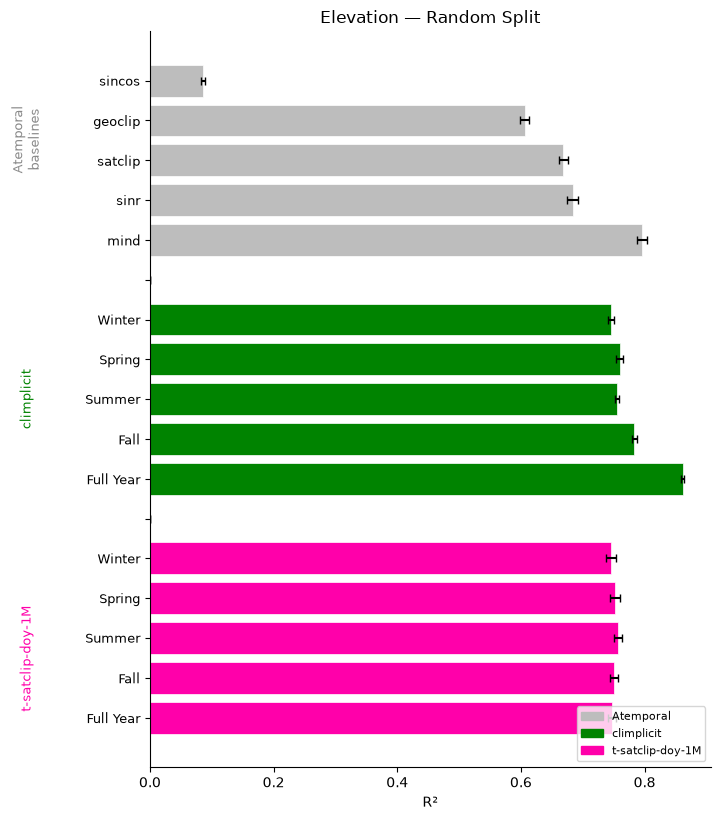

,group,model,season,R²,std
0,atemporal,sincos,-,0.086,0.003
1,atemporal,satclip,-,0.668,0.007
2,atemporal,geoclip,-,0.606,0.007
3,atemporal,mind,-,0.796,0.008
4,atemporal,sinr,-,0.684,0.009
8,climplicit,climplicit,Fall,0.783,0.004
5,climplicit,climplicit,Full Year,0.862,0.002
6,climplicit,climplicit,Spring,0.760,0.006
7,climplicit,climplicit,Summer,0.756,0.003
9,climplicit,climplicit,Winter,0.746,0.005


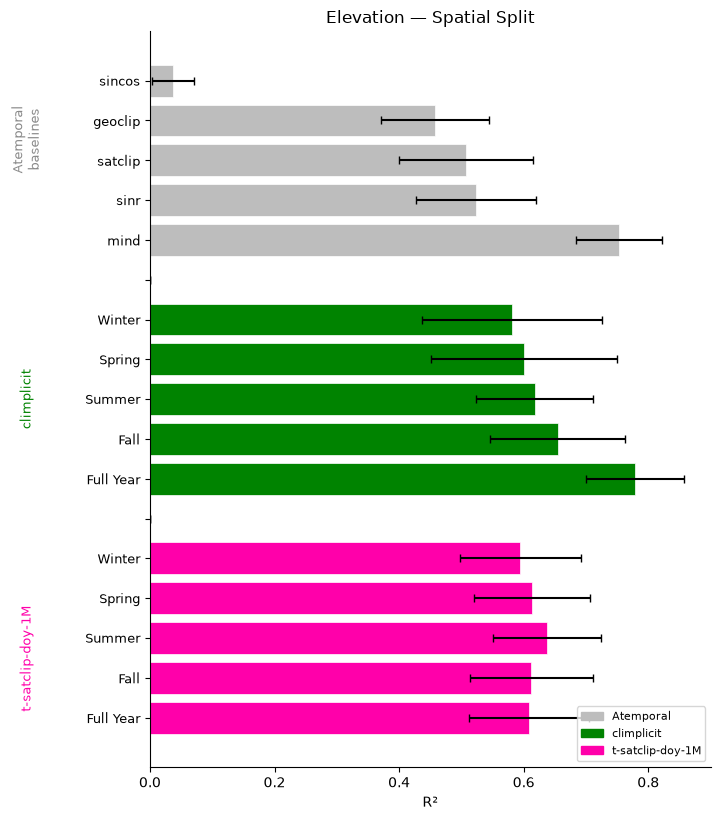

,group,model,season,R²,std
0,atemporal,sincos,-,0.038,0.034
1,atemporal,satclip,-,0.507,0.108
2,atemporal,geoclip,-,0.458,0.086
3,atemporal,mind,-,0.753,0.069
4,atemporal,sinr,-,0.523,0.096
8,climplicit,climplicit,Fall,0.655,0.108
5,climplicit,climplicit,Full Year,0.779,0.079
6,climplicit,climplicit,Spring,0.600,0.150
7,climplicit,climplicit,Summer,0.617,0.093
9,climplicit,climplicit,Winter,0.581,0.145


In [26]:
for split in ["random", "spatial"]:
    fig, table = plot_elevation(df, split)
    plt.show()
    display(table)

## Plot ERA5 results

In [27]:
df = pd.read_csv(f"{results_dir}/coordbench/era5_temporal_aggregation/era5_ecmwf.csv")

In [28]:
def get_windows(df):
    windows = ["1_week", "2_weeks", "4_weeks", "13_weeks"]
    df["window"] = df["dataset"].apply(lambda d: next(w for w in reversed(windows) if w in d))
    df["window_i"] = df["window"].map({w: i for i, w in enumerate(windows)})
    return df

In [29]:
df_no_antarctica = df[df["dataset"].str.contains("no_antarctica")]

In [30]:
df = get_windows(df)
df_no_antarctica = get_windows(df_no_antarctica)

In [31]:
var_groups = {
    "Temperature": ["t2m_mean", "d2m_mean", "skt_mean"],
    "Soil Temp": ["stl1_mean", "stl2_mean", "stl3_mean", "stl4_mean"],
    "Soil Moisture": ["swvl1_mean", "swvl2_mean", "swvl3_mean", "swvl4_mean"],
    "Radiation": ["ssrd_mean", "strd_mean"],
    "Precipitation & Snow": ["tp_mean", "sde_mean", "snowc_mean"],
    "Wind & Pressure": ["u10_mean", "v10_mean", "sp_mean"],
}

In [32]:
week_values = [1, 2, 4, 13]
window_to_weeks = {i: w for i, w in enumerate(week_values)}

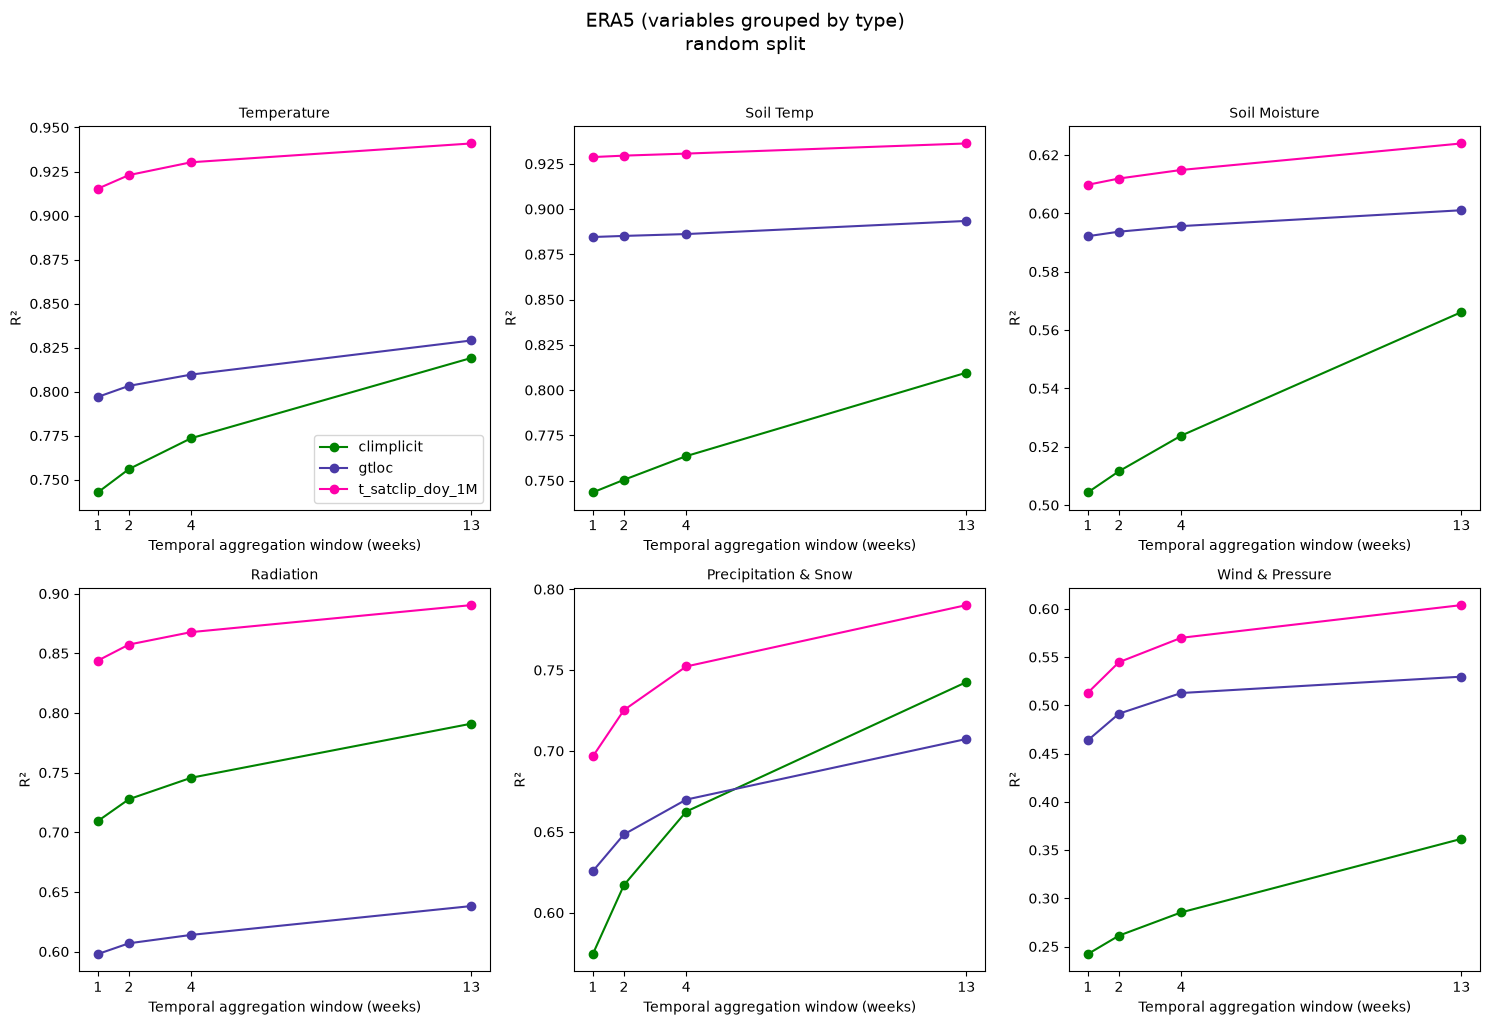

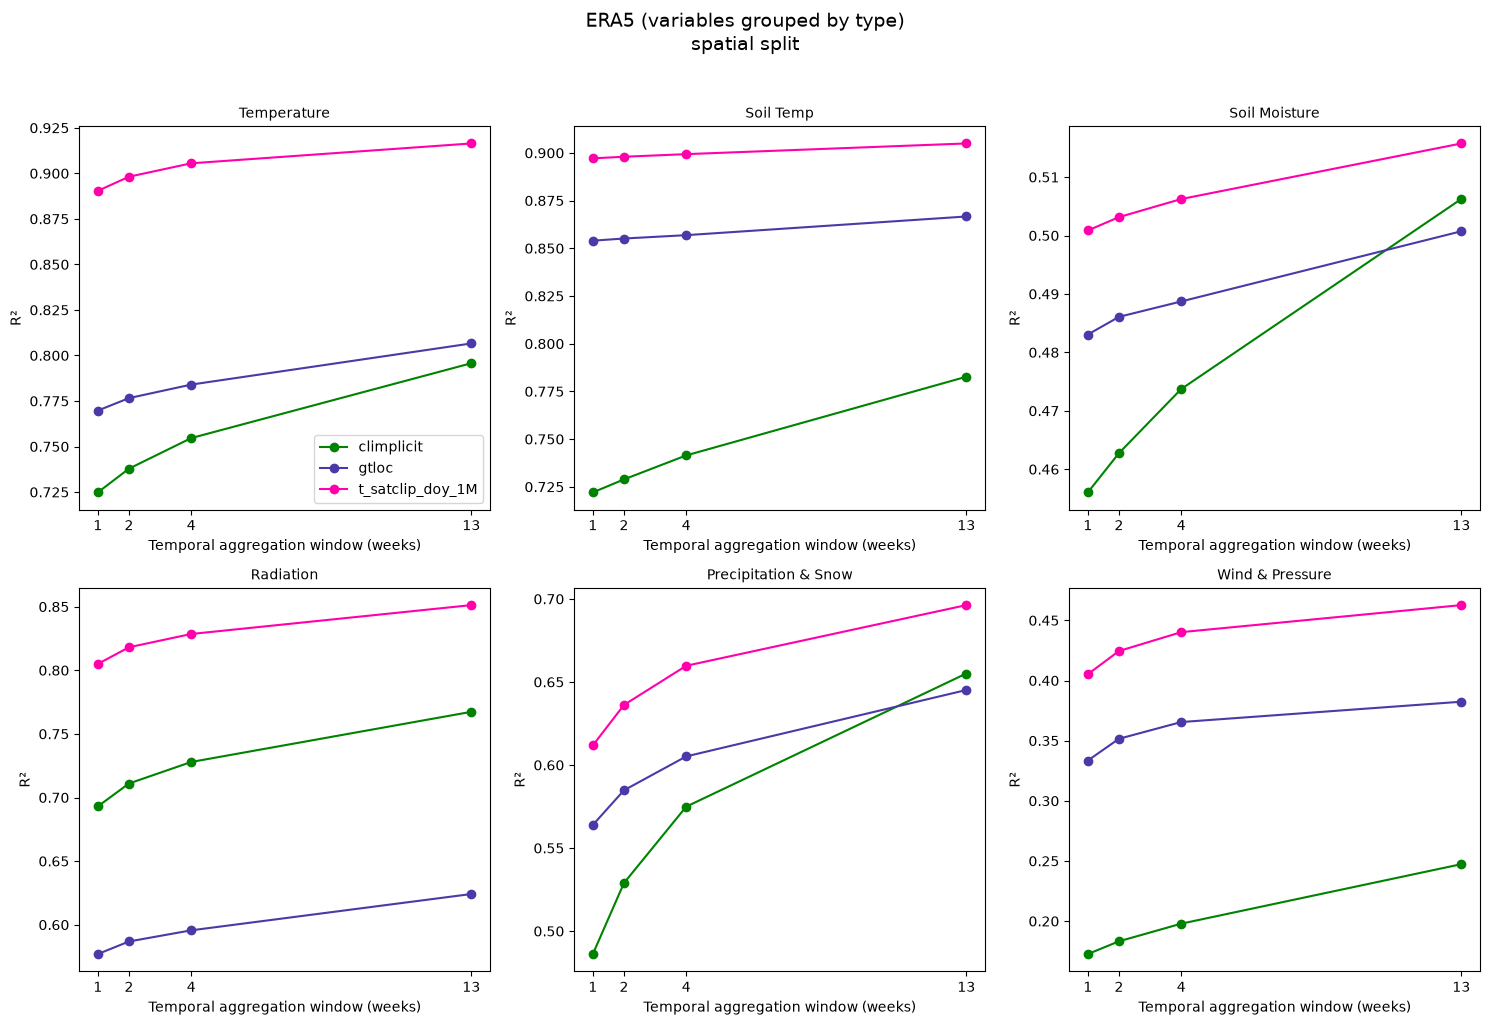

In [35]:
for split in ["random", "spatial"]:
    sub_split = df[df["split"] == split]

    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    for ax, (name, vlist) in zip(axes.flat, var_groups.items()):
        sub = sub_split[sub_split["task"].isin(vlist)]
        for model, mdf in sub.groupby("model_name"):
            avg = mdf.groupby("window_i")["metric_value"].mean()
            xs = [window_to_weeks[i] for i in avg.index]
            ax.plot(xs, avg.values, "o-", label=model, color=model_colors.get(model))

        ax.set_xticks(week_values)
        ax.set_xticklabels(week_values)
        ax.set_xlabel("Temporal aggregation window (weeks)")

        ax.set_title(name, fontsize=10)
        ax.set_ylabel("R²", fontsize=10)

    axes.flat[0].legend(fontsize=10)
    fig.suptitle(f"ERA5 (variables grouped by type)\n{split} split", fontsize=14, y=1.02)
    fig.tight_layout()
    plt.show()


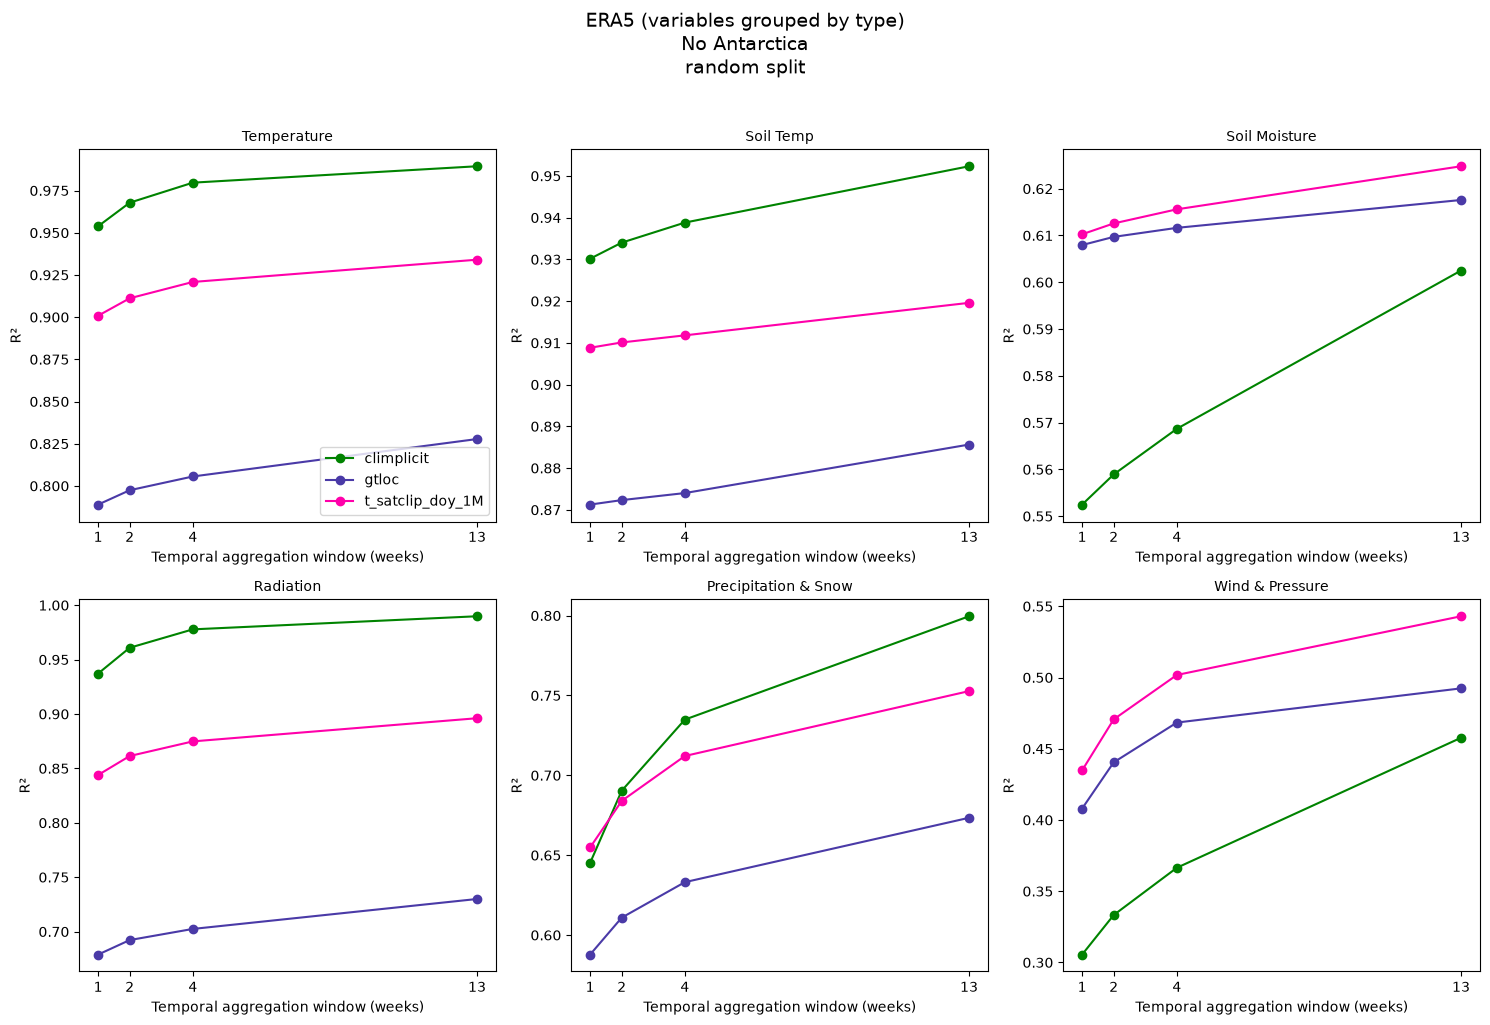

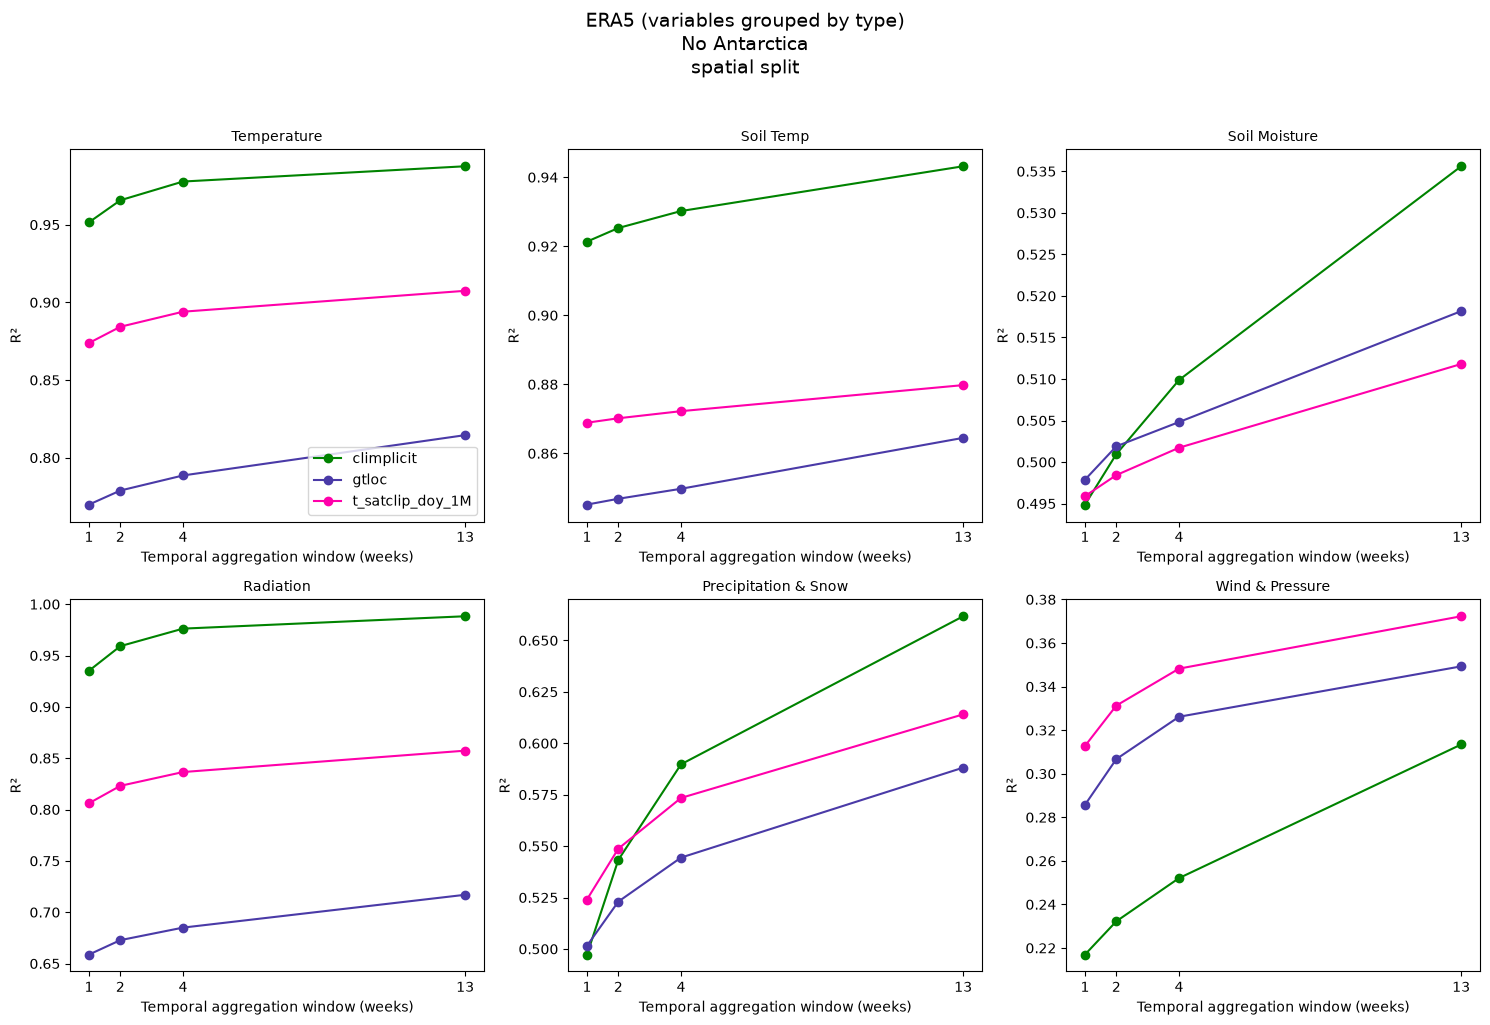

In [36]:
for split in ["random", "spatial"]:
    sub_split = df_no_antarctica[df_no_antarctica["split"] == split]

    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    for ax, (name, vlist) in zip(axes.flat, var_groups.items()):
        sub = sub_split[sub_split["task"].isin(vlist)]
        for model, mdf in sub.groupby("model_name"):
            avg = mdf.groupby("window_i")["metric_value"].mean()
            xs = [window_to_weeks[i] for i in avg.index]
            ax.plot(xs, avg.values, "o-", label=model, color=model_colors.get(model))

        ax.set_xticks(week_values)
        ax.set_xticklabels(week_values)
        ax.set_xlabel("Temporal aggregation window (weeks)")

        ax.set_title(name, fontsize=10)
        ax.set_ylabel("R²", fontsize=10)

    axes.flat[0].legend(loc="lower right", fontsize=10)
    fig.suptitle(f"ERA5 (variables grouped by type)\nNo Antarctica\n{split} split", fontsize=14, y=1.02)
    fig.tight_layout()
    plt.show()
